# UTS Graf Sains Data
**Nama :** Nadira Zahra Ramadhani

**NIM :** 23031554099

**Kelas :** 2023D


**Periode P1 (training) :** 17 Juli - 30 Juli  **Periode P2 (testing) :** 31 Juli - 6 Agustus

## 1. Tugas Pendahuluan
### 1.1 Persiapan Lingkungan

In [1]:
import sys
import neo4j
print("Python :", sys.version.split()[0])
print("Kernel :", sys.executable)
print("neo4j  :", neo4j.__version__)

Python : 3.11.9
Kernel : d:\Semester 7\Graph Sains Data\UTS GSD\myvenv\Scripts\python.exe
neo4j  : 6.4.1


In [2]:
from getpass import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = getpass("Password Neo4j: ")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
print("Terhubung ke Neo4j")

Terhubung ke Neo4j


### 1.2 Tutorial Driver Neo4j

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

for f in ["Guinevere", "Lancelot", "Merlin"]:
    add_friend(driver, "Arthur", f)
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**Pertanyaan Pendahuluan**
1. Database yang digunakan adalah `neo4j` karena itu database default dari parameter `database_="neo4j"`.

2. Database juga bisa diganti dengan `USE namadb`, `:use namadb`, atau lewat `driver.session(database=...)`. Untuk melihat database bisa menggunakan `SHOW DATABASES`, sedangkan untuk membuat database baru menggunakan `CREATE DATABASE`.

3. Jenis grafnya directed, unweighted, dan homogeneous karena hanya ada satu label `Person` dan satu relasi `KNOWS`. Grafnya simple karena menggunakan `MERGE`, dengan Arthur sebagai pusat yang terhubung ke node lainnya.

In [4]:
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
print("Database dibersihkan")

Database dibersihkan


### 1.3 Impor Data RetailRocket

In [5]:
import os
import pandas as pd

csv_path = os.path.join("data", "events.csv")
assert os.path.exists(csv_path), f"{csv_path} tidak ditemukan"

pd.read_csv(csv_path, nrows=5, dtype={"transactionid": str})

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [7]:
q_nodes = "MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah"
q_rels  = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"
for q in (q_nodes, q_rels):
    records, _, _ = driver.execute_query(q, database_="neo4j")
    for r in records:
        print(dict(r))

{'label': ['Visitor'], 'jumlah': 54913}
{'label': ['Item'], 'jumlah': 39559}
{'relasi': 'VIEWED', 'jumlah': 96754}
{'relasi': 'ADDED_TO_CART', 'jumlah': 2394}
{'relasi': 'BOUGHT', 'jumlah': 852}


---
## 2. Soal UTS
### 2.1 Wrangling dan EDA

#### 2.1.1 - 2.1.2 Filter Periode Waktu dan Simpan ke CSV

Kolom `timestamp` pada `events.csv` berupa unix epoch dalam **milidetik**, sehingga batas periode dikonversi ke milidetik (UTC) terlebih dahulu. Periode yang dipilih:

| Fold | Periode | Fungsi |
|---|---|---|
| P1 (training) | 17 Juli - 30 Juli 2015 | Membangun graf & similarity |
| P2 (testing) | 31 Juli - 6 Agustus 2015 | Ground truth evaluasi Hit@5 dan NDCG@5 |

Filter memakai interval setengah terbuka `[start, end)` agar tidak ada baris yang masuk ke dua periode sekaligus. File dibaca per *chunk* supaya hemat memori, lalu hasilnya disimpan ke `data/events_filtered.csv` dengan kolom tambahan `period`.

In [8]:
import pandas as pd

def to_ms(s):
    return int(pd.Timestamp(s, tz="UTC").timestamp() * 1000)

P1_START, P1_END = to_ms("2015-07-17"), to_ms("2015-07-31")  # 17-30 Juli
P2_START, P2_END = to_ms("2015-07-31"), to_ms("2015-08-07")  # 31 Jul-6 Agu

parts = []
for chunk in pd.read_csv(csv_path, chunksize=500_000, dtype={"transactionid": str}):
    ts = chunk["timestamp"]
    c1 = chunk[(ts >= P1_START) & (ts < P1_END)].assign(period="P1")
    c2 = chunk[(ts >= P2_START) & (ts < P2_END)].assign(period="P2")
    parts += [c1, c2]

df = pd.concat(parts, ignore_index=True)
df.to_csv("data/events_filtered.csv", index=False)
print(df.groupby(["period", "event"]).size())
print(df["visitorid"].nunique(), df["itemid"].nunique())

period  event      
P1      addtocart        8103
        transaction      2708
        view           312821
P2      addtocart        3607
        transaction      1121
        view           128132
dtype: int64
251195 100343


#### Reset Database dan Impor Ulang (P1)

Graf sebelumnya dibuat dari data tanpa filter, sehingga database dibersihkan terlebih dahulu. Hanya data **P1** yang diimpor ke Neo4j sebagai graf training. Data P2 tidak dimasukkan ke graf agar tidak terjadi *data leakage* saat evaluasi rekomendasi. Constraint `UNIQUE` dibuat pada `Visitor.visitorId` dan `Item.itemId` untuk menjaga keunikan simpul sekaligus mempercepat `MERGE`.

In [10]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [11]:
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")

with driver.session(database="neo4j") as session:
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

    train = df[df["period"] == "P1"].drop(columns="period")
    train["transactionid"] = train["transactionid"].fillna("").astype(str)

    batch_size = 5000
    for i in range(0, len(train), batch_size):
        records = train.iloc[i:i+batch_size].to_dict(orient="records")
        session.execute_write(import_batch, records) 

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row, v, i, row, v, i, row) { ... }', position=<SummaryInputPosition line=7, column=5, offset=139>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 139, 'line': 7, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n\n        UNION ALL\n\n 

#### 2.1.3 Komposisi Subgraph

Komposisi graf diambil lewat Python API (`driver.execute_query`) dengan dua query Cypher:

- `MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah`
  `MATCH (n)` mengambil seluruh simpul, `labels(n)[0]` mengambil label tiap simpul (`Visitor` / `Item`), dan `count(*)` dikelompokkan otomatis per label karena Cypher melakukan implicit grouping pada kolom non-agregat di `RETURN`.
- `MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah`
  Sama seperti di atas, tetapi untuk relasi: `type(r)` mengambil jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

In [12]:
q_nodes = "MATCH (n) RETURN labels(n)[0] AS label, count(*) AS jumlah"
q_rels  = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"
for q in (q_nodes, q_rels):
    records, _, _ = driver.execute_query(q, database_="neo4j")
    for r in records:
        print(dict(r))

{'label': 'Visitor', 'jumlah': 177851}
{'label': 'Item', 'jumlah': 82344}
{'relasi': 'VIEWED', 'jumlah': 312821}
{'relasi': 'ADDED_TO_CART', 'jumlah': 8103}
{'relasi': 'BOUGHT', 'jumlah': 2708}


#### Persiapan Vector Space Modelling (VSM)
Seluruh relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) pada graf P1 ditarik dari Neo4j lewat Python API, lalu dibentuk menjadi **matriks biadjacency biner** `B` berukuran `|Visitor| x |Item|`. Nilai `B[u, i] = 1` jika visitor `u` pernah berinteraksi dengan item `i` (jenis dan jumlah interaksi diabaikan, duplikat dijadikan 1). Matriks disimpan dalam format sparse (`scipy.sparse.csr_matrix`).

In [13]:
import numpy as np
import scipy.sparse as sp

q = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS rel
"""
records, _, _ = driver.execute_query(q, database_="neo4j")
edges = pd.DataFrame([dict(r) for r in records])

users = np.sort(edges["u"].unique())
items = np.sort(edges["i"].unique())
u_idx = {u: k for k, u in enumerate(users)}
i_idx = {i: k for k, i in enumerate(items)}

rows = edges["u"].map(u_idx).to_numpy()
cols = edges["i"].map(i_idx).to_numpy()

# biner: 1 kalau pernah berinteraksi (view/cart/buy), duplikat dijadikan 1
B = sp.csr_matrix((np.ones(len(edges)), (rows, cols)), shape=(len(users), len(items)))
B.data[:] = 1

print("Shape B (user x item):", B.shape)
print("Non-zero:", B.nnz, "| density:", B.nnz / (B.shape[0] * B.shape[1]))

Shape B (user x item): (177851, 82344)
Non-zero: 258439 | density: 1.76469551010556e-05


Hasil: shape `B` = **177.851 x 82.344**, non-zero = **258.439** (pasangan visitor-item unik, dari 323.632 relasi karena ada interaksi berulang pada pasangan yang sama), density = **1,76 x 10⁻⁵**.

#### 2.1.4 Vector Space Modelling: Visitor (User)
Graf bipartit P1 direpresentasikan sebagai matriks biner **B** (user × item) berukuran **177.851 × 82.344** dengan 258.439 entri non-zero (density ≈ 1,76 × 10⁻⁵). Dari 323.632 relasi (VIEWED + ADDED_TO_CART + BOUGHT), hanya 258.439 pasangan user-item yang unik, artinya ±20% relasi adalah interaksi berulang yang dilebur menjadi 1.

- **Dimensi vektor user:** 82.344 (satu dimensi per item). Shape matriks: (177.851, 82.344).
- **Isi vektor:** rata-rata hanya 1,45 item per user (median 1, maks 703), sehingga vektor user sangat *sparse* (>99,99% nol).
- **81,7% user hanya berinteraksi dengan 1 item**, jadi sebagian besar vektor user nyaris tidak punya informasi untuk dibandingkan.
- **Plot networkx:** 15 visitor teraktif saja sudah menyentuh ribuan item, sehingga graf menjadi gumpalan padat (*hairball*) yang tidak terbaca. Ini menunjukkan adanya *hub* ekstrem di sisi user, sementara mayoritas user lain hanya punya satu sisi.

In [14]:
deg_u = np.asarray(B.sum(axis=1)).ravel()
print("Dimensi vektor user :", B.shape[1])
print("Item/user -> rata2: %.2f | median: %d | max: %d" % (deg_u.mean(), np.median(deg_u), deg_u.max()))
print("User dengan 1 item saja: %.1f%%" % (100 * (deg_u == 1).mean()))

Dimensi vektor user : 82344
Item/user -> rata2: 1.45 | median: 1 | max: 703
User dengan 1 item saja: 81.7%


#### 2.1.5 Vector Space Modelling: Item
Representasi item adalah transpose **Bᵀ** (item × user) berukuran **82.344 × 177.851**.

- **Dimensi vektor item:** 177.851 (satu dimensi per visitor).
- **Isi vektor:** rata-rata 3,14 user per item (median 1, maks 473). Item lebih "padat" dibanding user, tetapi tetap sparse dengan distribusi *long-tail*.
- **52,3% item hanya dikunjungi 1 user**, lebih sedikit dibanding proporsi user dengan 1 item (81,7%).
- **Plot networkx:** 15 item terpopuler tampil sebagai hub berukuran besar dengan banyak visitor di sekelilingnya. Banyak visitor terhubung ke lebih dari satu hub populer (garis saling silang di tengah), sedangkan visitor di tepi hanya terhubung ke satu hub. Visitor yang menghubungkan beberapa item inilah yang menjadi dasar kemiripan antar-item.

In [15]:
deg_i = np.asarray(B.sum(axis=0)).ravel()
print("Dimensi vektor item :", B.shape[0])
print("User/item -> rata2: %.2f | median: %d | max: %d" % (deg_i.mean(), np.median(deg_i), deg_i.max()))
print("Item dengan 1 user saja: %.1f%%" % (100 * (deg_i == 1).mean()))

Dimensi vektor item : 177851
User/item -> rata2: 3.14 | median: 1 | max: 473
Item dengan 1 user saja: 52.3%


Matplotlib is building the font cache; this may take a moment.


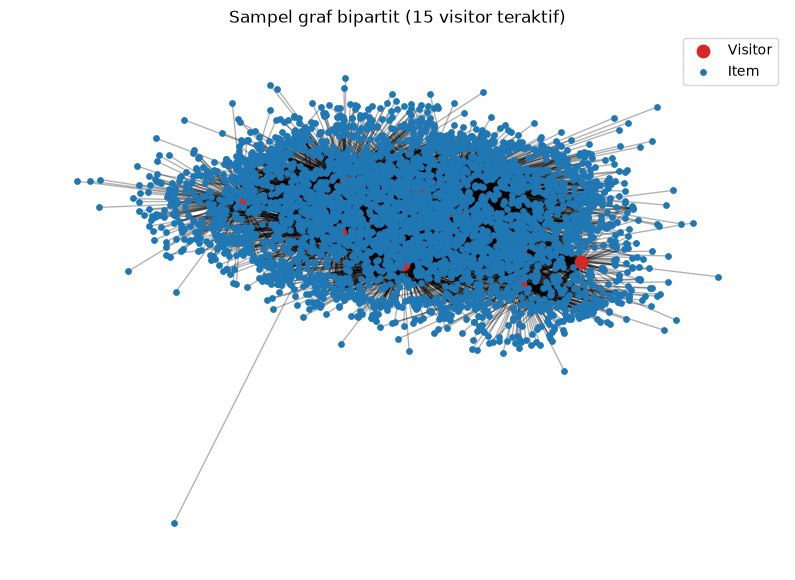

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

top_u = np.argsort(-deg_u)[:15]
sub = B[top_u]
G = nx.Graph()
for a, ui in enumerate(top_u):
    for ij in sub[a].indices:
        G.add_edge(f"U{users[ui]}", f"I{items[ij]}")

user_nodes = [n for n in G if n.startswith("U")]
item_nodes = [n for n in G if n.startswith("I")]
pos = nx.spring_layout(G, seed=42, k=0.3)
plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:red", node_size=80, label="Visitor")
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:blue", node_size=15, label="Item")
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.legend(); plt.title("Sampel graf bipartit (15 visitor teraktif)"); plt.axis("off"); plt.show()

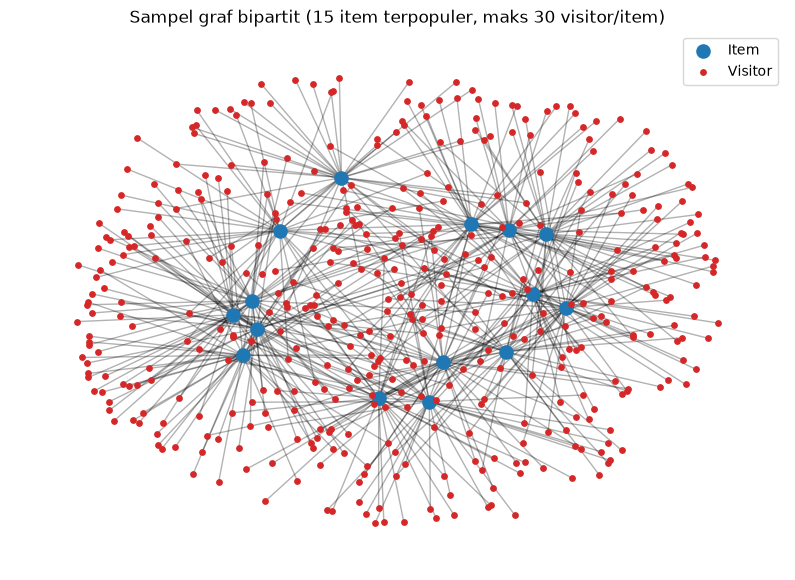

In [17]:
Bt = B.T.tocsr()  

top_i = np.argsort(-deg_i)[:15]
G = nx.Graph()
for a, ij in enumerate(top_i):
    us = Bt[ij].indices[:30]         
    for ui in us:
        G.add_edge(f"I{items[ij]}", f"U{users[ui]}")

item_nodes = [n for n in G if n.startswith("I")]
user_nodes = [n for n in G if n.startswith("U")]
pos = nx.spring_layout(G, seed=42, k=0.3)
plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="tab:blue", node_size=90, label="Item")
nx.draw_networkx_nodes(G, pos, nodelist=user_nodes, node_color="tab:red", node_size=15, label="Visitor")
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.legend(); plt.title("Sampel graf bipartit (15 item terpopuler, maks 30 visitor/item)")
plt.axis("off"); plt.show()

#### 2.1.6 Pemilihan Proyeksi: User-User vs Item-Item

In [18]:
d_u = deg_u.astype(np.int64)   # jumlah item per user
d_i = deg_i.astype(np.int64)   # jumlah user per item

pairs_user_proj = int((d_i * (d_i - 1) // 2).sum())   
pairs_item_proj = int((d_u * (d_u - 1) // 2).sum())   

conn_user = np.mean(np.asarray(B  @ (d_i >= 2).astype(float)).ravel() > 0)
conn_item = np.mean(np.asarray(Bt @ (d_u >= 2).astype(float)).ravel() > 0)

summary = pd.DataFrame({
    "Proyeksi": ["User-User (B·Bᵀ)", "Item-Item (Bᵀ·B)"],
    "Simpul": [B.shape[0], B.shape[1]],
    "Dimensi vektor": [B.shape[1], B.shape[0]],
    "Maks. sisi (pasangan)": [pairs_user_proj, pairs_item_proj],
    "% simpul punya tetangga": [100 * conn_user, 100 * conn_item],
    "Est. memori (MB)": [2 * pairs_user_proj * 12 / 1e6, 2 * pairs_item_proj * 12 / 1e6],
})
pd.options.display.float_format = "{:,.2f}".format
summary

,Proyeksi,Simpul,Dimensi vektor,Maks. sisi (pasangan),% simpul punya tetangga,Est. memori (MB)
0,User-User (B·Bᵀ),177851,82344,1992580,83.44,47.82
1,Item-Item (Bᵀ·B),82344,177851,1578919,51.30,37.89


Graf bipartit dapat diproyeksikan menjadi graf **User-User** (dua user terhubung jika berbagi item, matriks B·Bᵀ) atau **Item-Item** (dua item terhubung jika dipakai user yang sama, matriks Bᵀ·B).

| Kriteria | User-User | Item-Item |
|---|---|---|
| Jumlah simpul | 177.851 | 82.344 |
| Dimensi vektor | 82.344 | 177.851 |
| Maks. sisi (pasangan) | 1.992.580 | 1.578.919 |
| Estimasi memori | 47,82 MB | 37,89 MB |
| % simpul punya tetangga | 83,44% | 51,30% |
| % user punya ≥1 kandidat item baru | 63,00% | 63,00% |
| Rata-rata kandidat (yang punya) | 310,16 | 310,16 |

**Temuan penting:** cakupan kandidat kedua proyeksi *identik* (63%). Ini wajar karena keduanya menelusuri jalur dua langkah yang sama di graf bipartit (user → item → user → item). Artinya pilihan proyeksi tidak mengubah item mana yang *bisa* direkomendasikan, melainkan hanya cara menghitung dan menyimpan kemiripannya. Sekitar 37% user tidak mendapat kandidat sama sekali pada proyeksi mana pun, karena semua item mereka tidak pernah disentuh user lain (*cold-start*). Ini batas atas cakupan metode berbasis graf.

Persentase simpul yang punya tetangga lebih tinggi di User-User (83,44% vs 51,30%) karena dua user yang masing-masing hanya punya 1 item tetap terhubung jika itemnya sama, sedangkan sebuah item baru terhubung ke item lain jika ada user dengan ≥2 item yang menyentuhnya. Namun, tetangga user seperti itu tidak menambah informasi, sebab tidak membawa item baru.

**Keputusan: proyeksi Item-Item dipilih**, dengan alasan:
1. **Efisiensi:** simpul 2,2× lebih sedikit, sisi ±20,8% lebih sedikit, dan memori ±20,8% lebih kecil, padahal kandidat yang dihasilkan sama.
2. **Stabilitas:** katalog item relatif tetap, sedangkan user berganti-ganti dan 81,7% hanya punya 1 interaksi. Similarity item dihitung sekali dari P1 lalu bisa dipakai untuk user mana pun, termasuk user baru.
3. **Kualitas sinyal:** vektor item lebih informatif (rata-rata 3,14 user, dan hanya 52,3% item bersinyal tunggal) daripada vektor user (rata-rata 1,45 item, 81,7% bersinyal tunggal). Cosine pada vektor yang lebih padat lebih bermakna.
4. **Keterbacaan:** hasil kemiripan antar-item bisa disimpan sebagai relasi `SIMILAR_TO` dan langsung di-query.

In [ ]:
import time
t0 = time.time()
Bb = B.tocsr()

def coverage(R):
    """R: user x item (jumlah dukungan tetangga). Buang item yang sudah ada di riwayat."""
    R = (R - R.multiply(Bb)).tocsr()
    R.eliminate_zeros()
    n_cand = R.getnnz(axis=1)
    return np.mean(n_cand > 0), n_cand[n_cand > 0].mean()

Sb = (Bt @ Bb).tocsr(); Sb.setdiag(0); Sb.eliminate_zeros(); Sb.data[:] = 1
cov_item, avg_item = coverage(Bb @ Sb)
del Sb

N = (Bb @ Bt).tocsr(); N.setdiag(0); N.eliminate_zeros(); N.data[:] = 1
cov_user, avg_user = coverage(N @ Bb)
del N

print(pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "% user punya >=1 kandidat baru": [100 * cov_user, 100 * cov_item],
    "Rata2 jumlah kandidat (yang punya)": [avg_user, avg_item],
}).round(2))
print("Waktu: %.1f detik" % (time.time() - t0))

    Proyeksi  % user punya >=1 kandidat baru  \
0  User-User                           63.00   
1  Item-Item                           63.00   

   Rata2 jumlah kandidat (yang punya)  
0                              310.16  
1                              310.16  
Waktu: 4.9 detik


#### 2.1.7 Similarity pada graf terproyeksi

In [20]:
from sklearn.preprocessing import normalize

X = normalize(Bt, norm="l2")            
S = (X @ X.T).tocsr()                    
S.setdiag(0); S.eliminate_zeros()
print("Shape S:", S.shape, "| non-zero:", S.nnz)

def knn_items(idx, k=5):
    s, e = S.indptr[idx], S.indptr[idx + 1]
    cols, vals = S.indices[s:e], S.data[s:e]
    order = np.lexsort((cols, -vals))[:k]          
    return [(int(cols[o]), float(vals[o])) for o in order]

ref_idx = int(np.argmax(deg_i))
ref_id  = int(items[ref_idx])
print("Item acuan:", ref_id, "| jumlah visitor:", int(deg_i[ref_idx]))
for j, sc in knn_items(ref_idx):
    print(int(items[j]), round(sc, 4))

Shape S: (82344, 82344) | non-zero: 2999744
Item acuan: 149275 | jumlah visitor: 473
235200 0.0475
53394 0.046
122509 0.046
33 0.0325
36945 0.0325


##### 7a. Cypher 5 similarity tertinggi

In [21]:
Q_TOP5 = """
MATCH (ref:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
WITH ref, collect(DISTINCT u) AS refUsers
UNWIND refUsers AS u
MATCH (u)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE other <> ref
WITH ref, size(refUsers) AS nRef, other, count(DISTINCT u) AS shared
MATCH (other)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(ou:Visitor)
WITH other, shared, nRef, count(DISTINCT ou) AS nOther
RETURN other.itemId AS itemId, shared, nOther,
       toFloat(shared) / sqrt(toFloat(nRef) * nOther) AS cosine
ORDER BY cosine DESC, itemId ASC
LIMIT 5
"""
recs, _, _ = driver.execute_query(Q_TOP5, ref=ref_id, database_="neo4j")
top5_cy = pd.DataFrame([dict(r) for r in recs])
display(top5_cy)

py_scores = [sc for _, sc in knn_items(ref_idx)]
print("Cocok dengan hasil Python:", np.allclose(top5_cy["cosine"].values, py_scores))

,itemId,shared,nOther,cosine
0,235200,4,15,0.05
1,53394,1,1,0.05
2,122509,1,1,0.05
3,33,1,2,0.03
4,36945,1,2,0.03


Cocok dengan hasil Python: True


##### 7b. Tulis similarity ke graf (ambil snapshot sebelum/sesudah)

In [ ]:
Q_ASSOC = """
MATCH (ref:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
      -[:VIEWED|ADDED_TO_CART|BOUGHT]->(n:Item)
WHERE n.itemId IN $neigh
RETURN DISTINCT v.visitorId AS visitor, n.itemId AS item
"""
Q_SIM = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.score AS score ORDER BY score DESC
"""
Q_COUNT = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n"

neigh_ids = [int(x) for x in top5_cy["itemId"]]

def snapshot():
    a, _, _ = driver.execute_query(Q_ASSOC, ref=ref_id, neigh=neigh_ids, database_="neo4j")
    s, _, _ = driver.execute_query(Q_SIM, ref=ref_id, database_="neo4j")
    n = driver.execute_query(Q_COUNT, database_="neo4j").records[0]["n"]
    a = pd.DataFrame([dict(r) for r in a], columns=["visitor", "item"])
    a = a.groupby("item").head(3)           # maks 3 visitor/item agar plot terbaca
    s = pd.DataFrame([dict(r) for r in s], columns=["item", "score"])
    return {"assoc": a, "sim": s, "n_sim": n}

before = snapshot()
print("SEBELUM -> jumlah relasi SIMILAR_TO:", before["n_sim"])

Q_WRITE = """
MATCH (ref:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u:Visitor)
WITH ref, collect(DISTINCT u) AS refUsers
UNWIND refUsers AS u
MATCH (u)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other:Item)
WHERE other <> ref
WITH ref, size(refUsers) AS nRef, other, count(DISTINCT u) AS shared
MATCH (other)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(ou:Visitor)
WITH ref, other, shared, nRef, count(DISTINCT ou) AS nOther
WITH ref, other, shared, toFloat(shared) / sqrt(toFloat(nRef) * nOther) AS cosine
ORDER BY cosine DESC, other.itemId ASC
LIMIT 5
MERGE (ref)-[s:SIMILAR_TO]->(other)
SET s.score = cosine, s.metric = 'cosine', s.shared_visitors = shared, s.period = 'P1'
RETURN other.itemId AS itemId, s.score AS score, s.shared_visitors AS shared
"""
recs, _, _ = driver.execute_query(Q_WRITE, ref=ref_id, database_="neo4j")
display(pd.DataFrame([dict(r) for r in recs]))

after = snapshot()
print("SESUDAH -> jumlah relasi SIMILAR_TO:", after["n_sim"])

Q_CHECK = """
MATCH (:Item {itemId: $ref})-[s:SIMILAR_TO]->(n:Item)
RETURN n.itemId AS itemId, s.score AS score ORDER BY score DESC
"""
recs, _, _ = driver.execute_query(Q_CHECK, ref=ref_id, database_="neo4j")
display(pd.DataFrame([dict(r) for r in recs]))

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist. Verify that the spelling is correct.', position=<SummaryInputPosition line=2, column=34, offset=34>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 34, 'line': 2, 'column': 34}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\nMATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)\nRETURN b.itemId AS item, s.score AS score ORDER BY score DESC\n'
Received notification from DBMS server: <GqlStatusObject gql_status='01N52', status_description='warn: property key does not exist. The property `score` does not exist. Verify that the spelling i

SEBELUM -> jumlah relasi SIMILAR_TO: 0


,itemId,score,shared
0,235200,0.05,4
1,53394,0.05,1
2,122509,0.05,1
3,33,0.03,1
4,36945,0.03,1


SESUDAH -> jumlah relasi SIMILAR_TO: 5


,itemId,score
0,235200,0.05
1,53394,0.05
2,122509,0.05
3,33,0.03
4,36945,0.03


##### 2.1.8 Sebelum vs sesudah similarity

MATCH p = (:Item {itemId: 123})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(n:Item)

WHERE n.itemId IN [101, 102, 103, 104, 105]

RETURN p

LIMIT 25

![Hasil visualisasi](visualisation.png)

MATCH p = (:Item {itemId: 123})-[:SIMILAR_TO]->(:Item)

RETURN p

![Hasil visualisasi](visualisation1.png)

#### 2.2.1 Rekomendasi KNN untuk User Acak

**Proses pemilihan user secara acak (reproducible):**

1. Kandidat user dipilih dari user yang terdapat pada data P1 dan memiliki minimal satu item pada P2 yang belum pernah diinteraksikan di P1 serta termasuk dalam ruang item P1. Ketentuan ini diterapkan agar rekomendasi yang dihasilkan dapat dievaluasi menggunakan data interaksi pada P2 sebagai ground truth.
2. Daftar kandidat diurutkan terlebih dahulu, kemudian satu user dipilih menggunakan np.random.default_rng(42).choice(...). Penggunaan seed tetap (42) memastikan pemilihan user dapat direproduksi dengan hasil yang sama ketika kode dijalankan kembali dengan data dan proses yang sama.

**Algoritma rekomendasi (item-based KNN, k = 5):**

1. Mengambil seluruh item yang terdapat dalam riwayat interaksi user pada P1.
2. Untuk setiap item dalam riwayat tersebut, mencari lima item tetangga terdekat berdasarkan nilai cosine similarity pada matriks kemiripan (S) yang telah dibentuk pada Subbab 2.1.7.
3. Menghapus item yang sudah terdapat dalam riwayat interaksi user. Selanjutnya, skor rekomendasi setiap item dihitung dengan menjumlahkan nilai similarity dari item-item riwayat yang mengarah ke item tersebut.
4. Mengurutkan kandidat rekomendasi berdasarkan skor KNN. Lima item dengan skor tertinggi digunakan untuk evaluasi, sedangkan tiga item teratas dipilih sebagai rekomendasi yang ditampilkan atau diiklankan kepada user.

**Hasil rekomendasi:**

Berdasarkan proses pemilihan acak yang telah dilakukan, diperoleh 2.705 user kandidat dan user terpilih dengan ID 137360. User tersebut memiliki lima item dalam riwayat interaksi P1, yaitu 117730, 174206, 272421, 431017, dan 435624. Sementara itu, item yang menjadi ground truth pada P2 adalah 64747.

Hasil penerapan algoritma item-based KNN menunjukkan bahwa lima rekomendasi teratas memiliki skor masing-masing sebesar 0,80; 0,80; 0,58; 0,58; dan 0,58. Tiga item yang dipilih untuk ditampilkan atau diiklankan kepada user adalah 54052 dengan skor 0,80, 231998 dengan skor 0,80, dan 83738 dengan skor 0,58.

Berdasarkan hasil tersebut, item ground truth 64747 tidak muncul dalam daftar lima rekomendasi teratas. Dengan demikian, untuk user yang diuji ini, rekomendasi belum berhasil mencakup item yang terdapat pada data interaksi P2. Hasil ini merupakan evaluasi untuk satu user terpilih dan belum dapat digunakan untuk menyimpulkan kinerja algoritma KNN secara keseluruhan.

In [25]:
def history(uidx):
    return B.indices[B.indptr[uidx]:B.indptr[uidx + 1]]

def recommend(uidx, k=5, topn=5, explain=False):
    hist = set(history(uidx).tolist())
    score, src = {}, {}
    for h in hist:
        for j, sim in knn_items(h, k):
            if j in hist:
                continue                     
            score[j] = score.get(j, 0.0) + sim
            if sim > src.get(j, (None, -1))[1]:
                src[j] = (h, sim)
    ranked = sorted(score.items(), key=lambda x: (-x[1], x[0]))[:topn]
    return (ranked, src) if explain else [j for j, _ in ranked]

p2_items = (df[df["period"] == "P2"].groupby("visitorid")["itemid"].apply(set))

def truth_of(vid):
    """item P2 yang (a) ada di ruang item P1 dan (b) belum ada di riwayat P1 user"""
    hist = set(history(u_idx[vid]).tolist())
    return {i_idx[i] for i in p2_items[vid] if i in i_idx} - hist

cand = sorted(int(v) for v in p2_items.index if v in u_idx and truth_of(v))
print("User kandidat (ada di P1 & punya ground truth di P2):", len(cand))

SEED = 42
rng = np.random.default_rng(SEED)
target_vid = int(rng.choice(cand))
target_idx = u_idx[target_vid]
print("User terpilih:", target_vid)
print("Riwayat P1  :", [int(items[h]) for h in history(target_idx)])
truth = truth_of(target_vid)
print("Ground truth P2:", sorted(int(items[t]) for t in truth))

ranked, src = recommend(target_idx, k=5, topn=5, explain=True)
rec_table = pd.DataFrame({
    "rank": range(1, len(ranked) + 1),
    "itemId": [int(items[j]) for j, _ in ranked],
    "skor_KNN": [round(s, 4) for _, s in ranked],
    "mirip_dengan_item_riwayat": [int(items[src[j][0]]) for j, _ in ranked],
    "ada_di_P2": [j in truth for j, _ in ranked],
})
print("\n=== Top-5 rekomendasi ===")
display(rec_table)
print("=== 3 item yang diiklankan (k = 5) ===")
display(rec_table.head(3)[["rank", "itemId", "skor_KNN"]])

User kandidat (ada di P1 & punya ground truth di P2): 2705
User terpilih: 137360
Riwayat P1  : [117730, 174206, 272421, 431017, 435624]
Ground truth P2: [64747]

=== Top-5 rekomendasi ===


,rank,itemId,skor_KNN,mirip_dengan_item_riwayat,ada_di_P2
0,1,54052,0.80,431017,False
1,2,231998,0.80,431017,False
2,3,83738,0.58,174206,False
3,4,240755,0.58,174206,False
4,5,286057,0.58,431017,False


=== 3 item yang diiklankan (k = 5) ===


,rank,itemId,skor_KNN
0,1,54052,0.80
1,2,231998,0.80
2,3,83738,0.58


#### 2.2.2 Evaluasi Hit@5 dan NDCG@5

**Definisi:**

- **Hit@5** = 1 jika minimal satu dari lima item rekomendasi muncul dalam *ground truth*, yaitu item yang benar-benar diinteraksikan user pada P2. Jika tidak ada item yang cocok, nilainya 0.
- **NDCG@5** = DCG@5 / IDCG@5, dengan DCG@5 = Σ relᵢ / log₂(i+1) untuk posisi i = 1 hingga 5. IDCG@5 merupakan nilai DCG ideal jika item relevan berada pada posisi teratas.

**Hasil evaluasi user terpilih (`137360`):**

| Metrik | Nilai |
|---|---:|
| Hit@5 | 0 |
| NDCG@5 | 0.0000 |

Berdasarkan hasil evaluasi, user `137360` memperoleh nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0.0000. Hasil tersebut menunjukkan bahwa tidak ada item dalam lima rekomendasi teratas yang sesuai dengan *ground truth* user pada P2, yaitu item `64747`. Dengan demikian, rekomendasi yang dihasilkan belum berhasil menemukan item yang benar-benar diinteraksikan oleh user tersebut pada periode P2.

Evaluasi terhadap satu user hanya memberikan gambaran kinerja pada sampel tersebut. Oleh karena itu, evaluasi dilanjutkan dengan menghitung rata-rata kinerja pada 3.000 user acak menggunakan seed 42, serta membandingkannya dengan baseline popularitas.

**Perbandingan kinerja Item-KNN dan baseline popularitas:**

| Metode | Hit@5 | NDCG@5 |
|---|---:|---:|
| Item-KNN (k=5) | 0.03 | 0.02 |
| Baseline popularitas | 0.01 | 0.00 |

**Interpretasi:**

Berdasarkan hasil evaluasi terhadap 3.000 user acak, metode Item-KNN memperoleh nilai Hit@5 sebesar 0.03 dan NDCG@5 sebesar 0.02, sedangkan baseline popularitas memperoleh nilai Hit@5 sebesar 0.01 dan NDCG@5 sebesar 0.00. Hasil ini menunjukkan bahwa Item-KNN memiliki kinerja lebih baik dibandingkan baseline popularitas dalam menemukan item yang relevan pada lima rekomendasi teratas. Nilai Hit@5 Item-KNN sebesar 0.03 menunjukkan bahwa sekitar 3% sampel user memiliki setidaknya satu item relevan dalam Top-5 rekomendasi, dibandingkan sekitar 1% pada baseline popularitas.

Meskipun demikian, nilai kedua metrik masih tergolong rendah. Hal ini dapat berkaitan dengan karakteristik data yang sparse, yaitu sekitar 81,7% user hanya memiliki satu item dalam riwayat interaksi, serta periode P2 yang relatif singkat, yaitu tujuh hari. Kondisi tersebut membatasi informasi yang tersedia untuk mengenali pola kemiripan antaritem dan memprediksi interaksi berikutnya. Walaupun hasilnya masih rendah secara absolut, Item-KNN menunjukkan peningkatan dibandingkan baseline popularitas pada kedua metrik evaluasi.

In [26]:
def hit_at_k(rec, truth, k=5):
    return int(any(i in truth for i in rec[:k]))

def ndcg_at_k(rec, truth, k=5):
    dcg  = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:k]) if i in truth)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(truth), k)))
    return dcg / idcg if idcg > 0 else 0.0

rec_idx = [j for j, _ in ranked]
print(f"User {target_vid}")
print("Hit@5  :", hit_at_k(rec_idx, truth))
print("NDCG@5 : %.4f" % ndcg_at_k(rec_idx, truth))

rng2 = np.random.default_rng(SEED)
sample = rng2.choice(cand, size=min(3000, len(cand)), replace=False)
pop_order = np.argsort(-deg_i)

hits, ndcgs, hits_pop, ndcgs_pop = [], [], [], []
for v in sample:
    v = int(v); ui = u_idx[v]; t = truth_of(v)
    rec = recommend(ui, k=5, topn=5)
    hist = set(history(ui).tolist())
    pop = [j for j in pop_order[:50] if j not in hist][:5]
    hits.append(hit_at_k(rec, t));      ndcgs.append(ndcg_at_k(rec, t))
    hits_pop.append(hit_at_k(pop, t));  ndcgs_pop.append(ndcg_at_k(pop, t))

pd.DataFrame({
    "Metode": ["Item-KNN (k=5)", "Baseline popularitas"],
    "Hit@5":  [np.mean(hits), np.mean(hits_pop)],
    "NDCG@5": [np.mean(ndcgs), np.mean(ndcgs_pop)],
}).round(4)

User 137360
Hit@5  : 0
NDCG@5 : 0.0000


,Metode,Hit@5,NDCG@5
0,Item-KNN (k=5),0.03,0.02
1,Baseline popularitas,0.01,0.00
